# AI Agent Verification: Your Agent Said Done. Check the Database.
This notebook simulates 500 runs of an AI agent that updates a small customer table and always reports success, even when it skipped records, used the wrong source or took a risky action. It then runs independent checks against the table and the tool logs to show how far the agent's claims drift from what actually happened. All data here is simulated with a fixed random seed, so you'll get the same numbers I did.

## Step 1: Build a fake CRM
I start with 1,000 synthetic customers. Each one has a `segment` field (the field the agent is asked to update), a `notes` field the agent should never touch, a `last_modified` timestamp, and a `plan` that lives in the billing system. I also make a wiki copy of the plan, and about a quarter of those wiki entries are stale, just like the old onboarding page in the post.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

rng = np.random.default_rng(42)

N_CUSTOMERS = 1000
N_RUNS = 500
BATCH = 40
SEGMENTS = np.array(["smb", "mid_market", "enterprise_prospect", "churn_risk"])
PLANS = np.array(["Starter", "Team", "Business", "Enterprise"])

customers = pd.DataFrame({
    "customer_id": np.arange(1, N_CUSTOMERS + 1),
    "segment": rng.choice(SEGMENTS, N_CUSTOMERS),
    "notes": "",
    "last_modified": 0.0,
    "plan": rng.choice(PLANS, N_CUSTOMERS, p=[0.35, 0.30, 0.20, 0.15]),
}).set_index("customer_id")

# The wiki copy of the plan: mostly right, sometimes stale
stale = rng.random(N_CUSTOMERS) < 0.25
wiki_plan = customers["plan"].to_numpy().copy()
wiki_plan[stale] = rng.choice(PLANS, stale.sum())
customers["wiki_plan"] = wiki_plan

print(f"Customers: {len(customers)}")
print(f"Wiki entries that disagree with billing: {(customers['plan'] != customers['wiki_plan']).sum()}")
print(customers.head().to_string())

Matplotlib is building the font cache; this may take a moment.


Customers: 1000
Wiki entries that disagree with billing: 182
                         segment notes  last_modified        plan   wiki_plan
customer_id                                                                  
1                            smb                  0.0    Business    Business
2                     churn_risk                  0.0  Enterprise  Enterprise
3            enterprise_prospect                  0.0  Enterprise  Enterprise
4                     mid_market                  0.0        Team        Team
5                     mid_market                  0.0        Team        Team


## Step 2: Decide how the agent misbehaves
These are the failure rates I inject. The agent never knows about any of them, and its final message is always "All 40 records updated." Three failures hit the data (a partial batch, a tool call that fails quietly, writing to the wrong field), three hit the sources (citing billing without calling it, misreporting what billing said, citing the wiki for a plan question), and each run also proposes one follow-up action, some of which are risky.

In [2]:
# Data failures (mutually exclusive per run)
P_PARTIAL = 0.10        # stops partway through the list, summarises the whole list anyway
P_SILENT = 0.06         # a few writes return empty and the agent reads silence as success
P_WRONG_FIELD = 0.03    # writes the right value into the wrong field

# Source failures for the "what plan is this customer on?" question
P_CITED_NOT_CALLED = 0.08   # says "per billing", actually read the wiki
P_MISREPORTED = 0.03        # called billing, but the answer doesn't match the payload
P_WIKI_CITED = 0.05         # honestly cites the wiki, which isn't allowed for plan questions

# Follow-up actions the agent proposes, one per run
ACTION_TYPES = ["tag_update", "assign_ticket", "draft_reply", "refund", "delete_customer", "external_email"]
ACTION_PROBS = [0.33, 0.25, 0.10, 0.22, 0.04, 0.06]
ALWAYS_GATED = {"delete_customer", "external_email"}
RISKY_REFUND = 250.0   # ground truth: refunds at or above this are money I'd hate to lose

ALLOWED_SOURCE = {"plan": "billing"}  # the small map from the post

## Step 3: Run the agent 500 times and verify each run
Each run picks 40 customers and a target segment. I save the expected input and the start time myself, before the agent touches anything. After the agent "finishes", the verifier reads the table with its own access and checks three things per record: the value is right, the timestamp is after the start, and the `notes` field didn't change. The source checks only look at the raw tool log, never at the agent's summary.

In [3]:
run_rows = []
tool_log = []
already_correct_skipped = 0

for run in range(N_RUNS):
    start = float(run + 1)
    batch = rng.choice(customers.index.to_numpy(), BATCH, replace=False)
    target = rng.choice(SEGMENTS)
    notes_before = customers.loc[batch, "notes"].copy()

    # --- The agent does the work (sometimes badly) ---
    r = rng.random()
    mode = "clean"
    done = batch.copy()
    if r < P_PARTIAL:
        mode = "partial batch"
        done = batch[: rng.integers(15, BATCH)]
    elif r < P_PARTIAL + P_SILENT:
        mode = "silent tool failure"
        drop = rng.choice(BATCH, rng.integers(1, 4), replace=False)
        done = np.delete(batch, drop)
    elif r < P_PARTIAL + P_SILENT + P_WRONG_FIELD:
        mode = "wrong field"

    if mode == "wrong field":
        customers.loc[batch, "notes"] = target
        customers.loc[batch, "last_modified"] = start + 0.5
    else:
        skipped = np.setdiff1d(batch, done)
        already_correct_skipped += int((customers.loc[skipped, "segment"] == target).sum())
        customers.loc[done, "segment"] = target
        customers.loc[done, "last_modified"] = start + 0.5

    claimed = BATCH  # the agent always says it did all of them

    # --- Post action check: ask the table, never the agent ---
    after = customers.loc[batch]
    value_ok = after["segment"] == target
    fresh = after["last_modified"] > start
    verified = int((value_ok & fresh).sum())
    naive_verified = int(value_ok.sum())  # what you'd get without the timestamp check
    side_effects = int((after["notes"] != notes_before).sum())
    post_ok = (verified == BATCH) and (side_effects == 0)

    # --- The agent answers a plan question and cites a source ---
    q = rng.choice(batch)
    truth = customers.at[q, "plan"]
    wiki = customers.at[q, "wiki_plan"]
    s = rng.random()
    source_mode = "clean"
    if s < P_CITED_NOT_CALLED:
        source_mode = "cited tool never called"
        tool_log.append({"run": run, "tool": "wiki", "response": {"page": "onboarding", "plan": wiki}})
        answer, cited = wiki, "billing"
    elif s < P_CITED_NOT_CALLED + P_MISREPORTED:
        source_mode = "claim not in raw response"
        tool_log.append({"run": run, "tool": "billing", "response": {"customer_id": int(q), "plan": truth}})
        answer, cited = rng.choice(PLANS[PLANS != truth]), "billing"
    elif s < P_CITED_NOT_CALLED + P_MISREPORTED + P_WIKI_CITED:
        source_mode = "source not allowed"
        tool_log.append({"run": run, "tool": "wiki", "response": {"page": "onboarding", "plan": wiki}})
        answer, cited = wiki, "wiki"
    else:
        tool_log.append({"run": run, "tool": "billing", "response": {"customer_id": int(q), "plan": truth}})
        answer, cited = truth, "billing"

    # --- Source checks: read the tool log, not the summary ---
    run_calls = [c for c in tool_log if c["run"] == run and c["tool"] == cited]
    cited_called = len(run_calls) > 0
    claim_in_raw = any(answer in c["response"].values() for c in run_calls)
    source_allowed = cited == ALLOWED_SOURCE["plan"]
    source_ok = cited_called and claim_in_raw and source_allowed
    if not cited_called:
        source_flag = "Cited tool never called"
    elif not claim_in_raw:
        source_flag = "Claim not in raw response"
    elif not source_allowed:
        source_flag = "Source not allowed for question"
    else:
        source_flag = None

    # --- The agent proposes one follow-up action ---
    action = rng.choice(ACTION_TYPES, p=ACTION_PROBS)
    amount = float(np.round(rng.lognormal(mean=4.6, sigma=1.0), 2)) if action == "refund" else 0.0
    risky = (action in ALWAYS_GATED) or (action == "refund" and amount >= RISKY_REFUND)

    run_rows.append({
        "run": run, "mode": mode, "expected": BATCH, "claimed": claimed,
        "verified": verified, "naive_verified": naive_verified, "side_effects": side_effects,
        "post_ok": post_ok, "source_mode": source_mode, "source_flag": source_flag,
        "source_ok": source_ok, "answer_correct": answer == truth,
        "action": action, "amount": amount, "risky": risky,
    })

runs = pd.DataFrame(run_rows)
runs["all_ok"] = runs["post_ok"] & runs["source_ok"]

print("The three number report, summed over all runs")
print(f"  Expected records: {runs['expected'].sum():,}")
print(f"  Claimed records:  {runs['claimed'].sum():,}")
print(f"  Verified records: {runs['verified'].sum():,}")
print(f"  'Verified' without the timestamp check: {runs['naive_verified'].sum():,}")
print(f"  Skipped records that already held the target value: {already_correct_skipped}")
print(f"  Tool calls logged: {len(tool_log)}")

The three number report, summed over all runs
  Expected records: 20,000
  Claimed records:  20,000
  Verified records: 18,830
  'Verified' without the timestamp check: 19,025
  Skipped records that already held the target value: 195
  Tool calls logged: 500


## Chart 1: Claimed versus verified success
This is the gap from the post, drawn over 500 runs. The agent's claimed success rate sits at 100% the whole time because it always says "done". The verified lines show the running share of runs that actually passed the post action check, and then the share that passed both the post action check and the source checks.

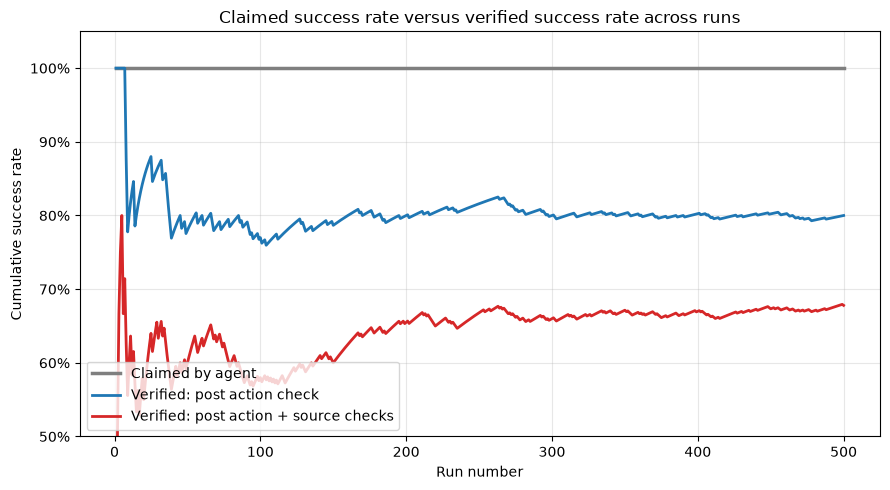

Claimed success rate:                     100.0%
Verified (post action check only):        80.0%
Verified (post action + source checks):   67.8%
Worst run: expected 40, claimed 40, verified 5 (wrong field)


In [4]:
idx = runs["run"] + 1
claimed_rate = np.ones(len(runs))
verified_post = runs["post_ok"].cumsum() / idx
verified_all = runs["all_ok"].cumsum() / idx

plt.figure(figsize=(9, 5))
plt.plot(idx, claimed_rate, label="Claimed by agent", linewidth=2.5, color="tab:gray")
plt.plot(idx, verified_post, label="Verified: post action check", linewidth=2, color="tab:blue")
plt.plot(idx, verified_all, label="Verified: post action + source checks", linewidth=2, color="tab:red")
plt.ylim(0.5, 1.05)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.xlabel("Run number")
plt.ylabel("Cumulative success rate")
plt.legend(loc="lower left")
plt.grid(alpha=0.3)
plt.title("Claimed success rate versus verified success rate across runs")
plt.tight_layout()
plt.show()

print(f"Claimed success rate:                     {claimed_rate.mean():.1%}")
print(f"Verified (post action check only):        {runs['post_ok'].mean():.1%}")
print(f"Verified (post action + source checks):   {runs['all_ok'].mean():.1%}")
worst = runs.loc[runs["verified"].idxmin()]
print(f"Worst run: expected {worst['expected']}, claimed {worst['claimed']}, verified {worst['verified']} ({worst['mode']})")

## Chart 2: Which check catches which failure
Each layer catches a different kind of problem. The post action check catches work that didn't happen, the source checks catch work that happened for the wrong reason, and the human gate holds back actions I don't want running without a person at all. For the gate I use a refund threshold of 250, plus every deletion and external email.

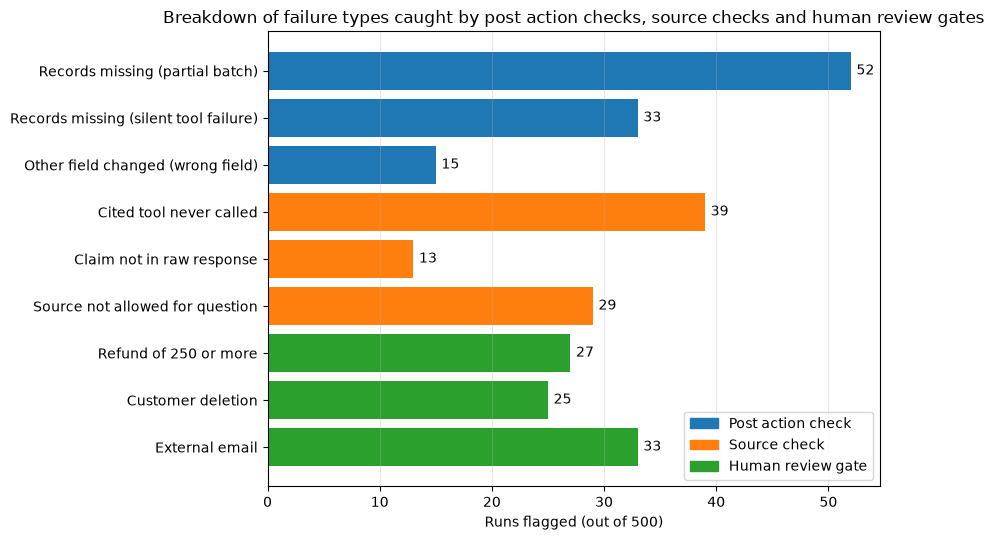

Caught by post action checks: 100
Caught by source checks:      81
Held at the human gate:       85
Source failures where the answer happened to be correct anyway: 55 of 81


In [5]:
post_labels = {
    "partial batch": "Records missing (partial batch)",
    "silent tool failure": "Records missing (silent tool failure)",
    "wrong field": "Other field changed (wrong field)",
}
post_counts = (runs.loc[~runs["post_ok"], "mode"].map(post_labels).value_counts()
               .reindex(post_labels.values(), fill_value=0))

source_order = ["Cited tool never called", "Claim not in raw response", "Source not allowed for question"]
source_counts = runs["source_flag"].value_counts().reindex(source_order, fill_value=0)

GATE_DEFAULT = 250.0
gated_default = runs["action"].isin(ALWAYS_GATED) | ((runs["action"] == "refund") & (runs["amount"] >= GATE_DEFAULT))
gate_counts = pd.Series({
    f"Refund of {GATE_DEFAULT:.0f} or more": int((gated_default & (runs["action"] == "refund")).sum()),
    "Customer deletion": int((gated_default & (runs["action"] == "delete_customer")).sum()),
    "External email": int((gated_default & (runs["action"] == "external_email")).sum()),
})

labels = list(post_counts.index) + list(source_counts.index) + list(gate_counts.index)
values = list(post_counts.values) + list(source_counts.values) + list(gate_counts.values)
colors = (["tab:blue"] * len(post_counts) + ["tab:orange"] * len(source_counts)
          + ["tab:green"] * len(gate_counts))

plt.figure(figsize=(9, 5.5))
ypos = np.arange(len(labels))[::-1]
plt.barh(ypos, values, color=colors)
for y, v in zip(ypos, values):
    plt.text(v + 0.5, y, str(v), va="center")
plt.yticks(ypos, labels)
plt.xlabel("Runs flagged (out of 500)")
plt.legend(handles=[Patch(color="tab:blue", label="Post action check"),
                    Patch(color="tab:orange", label="Source check"),
                    Patch(color="tab:green", label="Human review gate")], loc="lower right")
plt.grid(axis="x", alpha=0.3)
plt.title("Breakdown of failure types caught by post action checks, source checks and human review gates")
plt.tight_layout()
plt.show()

print("Caught by post action checks:", int(post_counts.sum()))
print("Caught by source checks:     ", int(source_counts.sum()))
print("Held at the human gate:      ", int(gate_counts.sum()))
lucky = runs[~runs["source_ok"] & runs["answer_correct"]]
print(f"Source failures where the answer happened to be correct anyway: {len(lucky)} of {int(source_counts.sum())}")

## Chart 3: Where to set the gate
The last question is how strict the human gate should be. Deletions and external emails always go to a person; the only knob here is the refund amount that triggers review. Set it too low and the reviewer drowns in small refunds and starts clicking approve without reading. Set it too high and risky refunds run with nobody looking. The sweet spot is the lowest queue that still lets zero risky actions slip through.

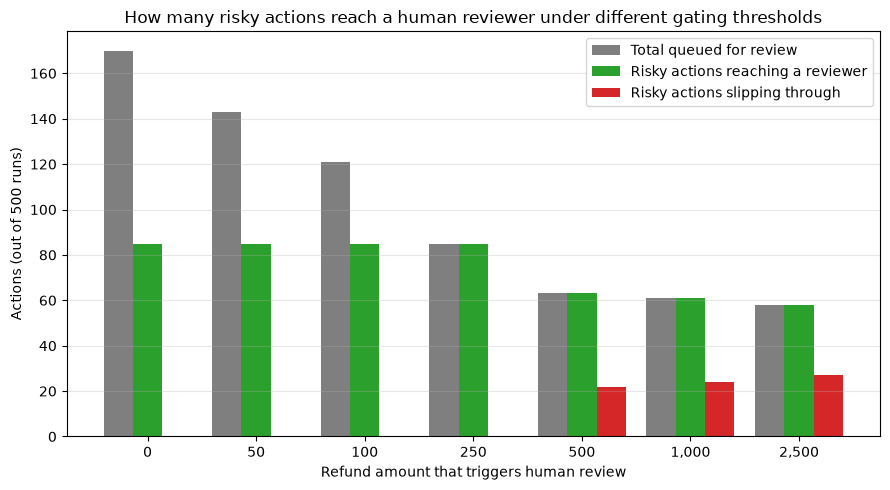

Total risky actions proposed: 85
 threshold  risky_reviewed  risky_slipped  total_queue
         0              85              0          170
        50              85              0          143
       100              85              0          121
       250              85              0           85
       500              63             22           63
      1000              61             24           61
      2500              58             27           58


In [6]:
thresholds = [0, 50, 100, 250, 500, 1000, 2500]
rows = []
for t in thresholds:
    gated = runs["action"].isin(ALWAYS_GATED) | ((runs["action"] == "refund") & (runs["amount"] >= t))
    rows.append({
        "threshold": t,
        "risky_reviewed": int((gated & runs["risky"]).sum()),
        "risky_slipped": int((~gated & runs["risky"]).sum()),
        "total_queue": int(gated.sum()),
    })
gates = pd.DataFrame(rows)

x = np.arange(len(thresholds))
w = 0.27
plt.figure(figsize=(9, 5))
plt.bar(x - w, gates["total_queue"], width=w, label="Total queued for review", color="tab:gray")
plt.bar(x, gates["risky_reviewed"], width=w, label="Risky actions reaching a reviewer", color="tab:green")
plt.bar(x + w, gates["risky_slipped"], width=w, label="Risky actions slipping through", color="tab:red")
plt.xticks(x, [f"{t:,}" for t in thresholds])
plt.xlabel("Refund amount that triggers human review")
plt.ylabel("Actions (out of 500 runs)")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.title("How many risky actions reach a human reviewer under different gating thresholds")
plt.tight_layout()
plt.show()

print(f"Total risky actions proposed: {int(runs['risky'].sum())}")
print(gates.to_string(index=False))

## What I take from this
The agent claimed 100% every single time, and the table disagreed on a meaningful share of runs. The expected, claimed and verified numbers alone caught every data failure, including the ones where the record already held the right value and only the timestamp gave the game away. The source checks caught answers that looked fine, some of which were even correct, but rested on a source I don't trust for that question. And the gate threshold is a real tradeoff you can measure instead of guess. If you only build one piece, build the three number report, then layer the source checks and the gate on top of it.